In [ ]:
# SS3 PART B 

# SS3 Part B: STADIOalot Client Data

# 1. Loading the Data

This section loads the customer data provided by STADIOalot.

- We will load table1_clickstream_search.cs,which contains information about how users behave during their website visits.
- We will load table3_product_catalogue.csv, which contains information about the products.
- The target variable is abandoned_session. True means the user left the website without buying anything.
- The dataset contains 45,691 clickstream records and 1,043 product records.
- We will check how many users left without buying and how many stayed and completed their purchases. This helps us understand the difference between the two groups.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, f1_score, auc
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# Define the path to the data
data_path = '/Users/mohau/Desktop/STADIOalot-Capstone/datasets/SS3_Data/'

# Load the Excel files (NOTE: read_excel and .xlsx)
df_clickstream = pd.read_excel(data_path + 'table1_clickstream_search.xlsx')
df_catalogue = pd.read_excel(data_path + 'table3_product_catalogue.xlsx')

print("Clickstream dataset shape:", df_clickstream.shape)
print("Product catalogue dataset shape:", df_catalogue.shape)

# Check target imbalance
print("\nTarget distribution (Abandoned Session):")
print(df_clickstream['abandoned_session'].value_counts(dropna=False))
print("\nTarget proportion:")
print(df_clickstream['abandoned_session'].value_counts(normalize=True))

Clickstream dataset shape: (45691, 10)
Product catalogue dataset shape: (1043, 13)

Target distribution (Abandoned Session):
abandoned_session
NaN    33248
1.0     9283
0.0     3160
Name: count, dtype: int64

Target proportion:
abandoned_session
1.0    0.746042
0.0    0.253958
Name: proportion, dtype: float64


# 2. Dataset Preprocessing

This section prepares the data so that the model is able to use it correctly.

1. Handling the target variable: The `abandoned_session` value only appears on the last page a user visits during a session. We remove rows with missing values so that each completed session has one row.

2. Removing data leakage: We remove `transaction_id` and `order_value` because they contain information about purchases. Keeping them could allow the model to predict the outcome unfairly.

3. Merging the datasets: We combine the clickstream data with the product catalogue using `product_viewed` (the product's SKU). This adds product details such as category, price, seller rating, and number of reviews.

4. Handling missing values and encoding: We replace missing numerical values with the median and missing category values with "Unknown". We also convert text categories into numbers so the model can understand them.

5. Splitting the data: We divide the data into three groups:

- 70% Training: To teach the model.
- 15% Validation: To check and improve the model.
- 15% Testing: To evaluate how well the model performs on data it has not seen before.

In [13]:
# 1. Drop rows where the target is NaN to get one row per session
df_sessions = df_clickstream.dropna(subset=['abandoned_session']).copy()

# 2. Drop leakage columns (transaction_id and order_value only exist if they bought)
df_sessions = df_sessions.drop(columns=['transaction_id', 'order_value'], errors='ignore')

# 3. Merge with catalogue to get product features
df_sessions = df_sessions.merge(
    df_catalogue[['sku', 'category', 'price', 'seller_rating', 'number_of_reviews']], 
    left_on='product_viewed', 
    right_on='sku', 
    how='left'
)

# Drop non-predictive ID columns and redundant merged SKU
df_sessions = df_sessions.drop(columns=['sku', 'timestamp', 'session_id', 'user_id', 'search_term', 'product_viewed'])

# 4. Handle missing values
# Numerical columns -> fill with median
num_cols = ['price', 'seller_rating', 'number_of_reviews']
for col in num_cols:
    df_sessions[col] = df_sessions[col].fillna(df_sessions[col].median())

# Categorical columns -> fill with 'Unknown'
cat_cols = ['traffic_source', 'category']
for col in cat_cols:
    df_sessions[col] = df_sessions[col].fillna('Unknown')

# 5. Encode Categorical variables and Booleans
le = LabelEncoder()
df_sessions['traffic_source'] = le.fit_transform(df_sessions['traffic_source'].astype(str))
df_sessions['category'] = le.fit_transform(df_sessions['category'].astype(str))
df_sessions['added_to_basket'] = df_sessions['added_to_basket'].astype(int)
df_sessions['abandoned_session'] = df_sessions['abandoned_session'].astype(int)

# 6. Split into Features (X) and Target (y)
X = df_sessions.drop(columns=['abandoned_session'])
y = df_sessions['abandoned_session']

# 7. Train / Validation / Test Split (70% Train, 15% Val, 15% Test)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Validation set: {X_val.shape[0]} rows")
print(f"Test set: {X_test.shape[0]} rows")
print(f"\nFeatures used for modeling:\n{list(X.columns)}")

Training set: 8710 rows
Validation set: 1866 rows
Test set: 1867 rows

Features used for modeling:
['traffic_source', 'added_to_basket', 'category', 'price', 'seller_rating', 'number_of_reviews']


#3. Model Training

In SS2, the HistGradientBoostingClassifier (Gradient Boosting) significantly outperformed Logistic Regression. Therefore, we will apply this final chosen method to the STADIOalot client data.

Hyperparameter Justification:
max_iter=100 : Provides enough boosting stages to learn complex patterns without overfitting on this dataset (~8,700 training rows).
max_depth=6: Allows the trees to capture feature interactions (e.g., traffic source vs. product category) while preventing extreme overfitting.
learning_rate=0.1: A standard shrinkage parameter that ensures the model learns steadily without overshooting the optimal solution.
class_weight='balanced': The dataset has a 75/25 class imbalance (75% abandoned). This parameter automatically adjusts weights to ensure the model doesn't just predict the majority class.
random_state=42: Ensures reproducibility.

In [14]:
# Initialize the final chosen model from SS2
model = HistGradientBoostingClassifier(
    max_iter=100,
    max_depth=6,
    learning_rate=0.1,
    class_weight='balanced',
    random_state=42
)

# Train the model on the training subset
model.fit(X_train, y_train)

print("Model training complete!")
print(f"Model trained on {X_train.shape[0]} samples with {X_train.shape[1]} features.")

Model training complete!
Model trained on 8710 samples with 6 features.


4. Model Validation
We test the trained model using 1,867 rows of data that it has not seen before. This helps us check how well the model predicts abandoned sessions.

Metrics used:

- Classification Report (Precision, Recall, F1-score): Shows how well the model makes predictions. Recall measures how many abandoned sessions the model correctly identifies. Precision measures how many sessions predicted as abandoned were actually abandoned. The F1-score combines precision and recall into one score.

- AUC-ROC: Measures how well the model can distinguish between abandoned and completed sessions. A higher score means better performance.

- Confusion Matrix: Shows the number of correct and incorrect predictions, including true positives, true negatives, false positives, and false negatives.

In [15]:
# 1. Predict on the unseen test set
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 2. Print Metrics
print("MODEL VALIDATION RESULTS (TEST SET)")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_test, y_prob):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 3. Print Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

MODEL VALIDATION RESULTS (TEST SET)
Accuracy:  0.6031
AUC-ROC:   0.5646

Classification Report:
              precision    recall  f1-score   support

           0       0.32      0.49      0.39       474
           1       0.79      0.64      0.71      1393

    accuracy                           0.60      1867
   macro avg       0.55      0.57      0.55      1867
weighted avg       0.67      0.60      0.63      1867

Confusion Matrix:
[[232 242]
 [499 894]]


# 5. Visualising the Results

We will use two graphs to show how well the model performs and help the business understand the results.

1. Confusion Matrix: Shows how many sessions the model predicted correctly and how many it predicted incorrectly.

2. ROC Curve: Shows the balance between correctly identifying abandoned sessions and incorrectly identifying completed sessions as abandoned. It helps us understand how changing the prediction threshold affects the model's performance.

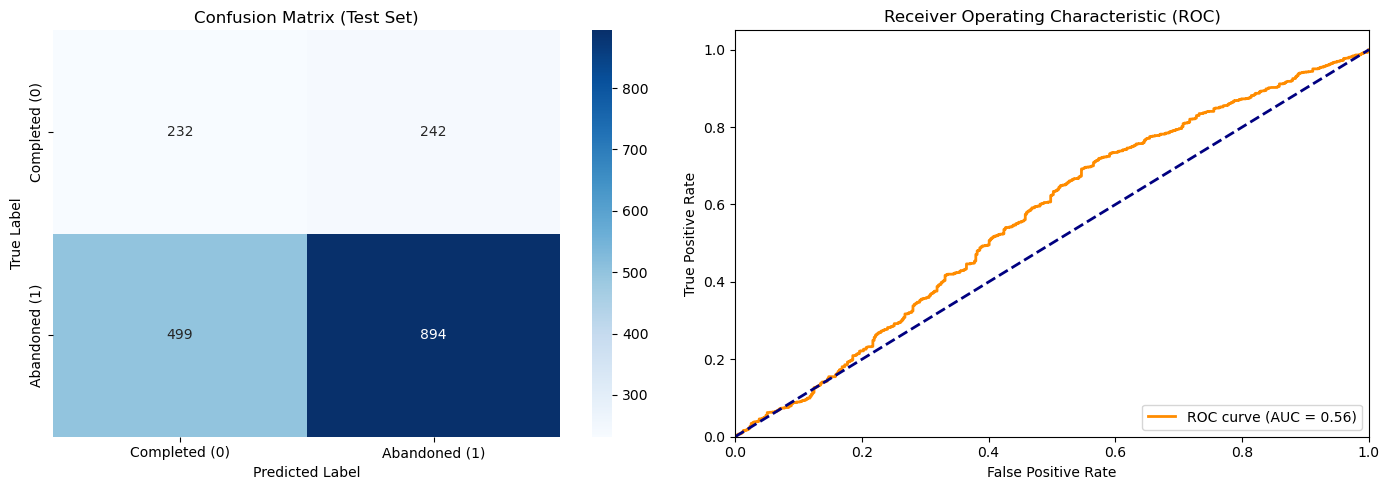

In [16]:
# Set up the figure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix (Test Set)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')
axes[0].set_xticklabels(['Completed (0)', 'Abandoned (1)'])
axes[0].set_yticklabels(['Completed (0)', 'Abandoned (1)'])

# 2. ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()